# MGS 670 — Project 2: Attention and Word2Vec for Hospital Length of Stay
**Reference:** Project 1 notebook and Project 2 assignment/rubric.  
**Outcome:** total hospital length of stay in days, predicted at admission.  
**Evaluation:** five independent shuffled patient-level folds; MSE/RMSE and training-MSE mean ± SD.  
**Design safeguard:** daily measurements collected after admission are *not* used to predict admission-time HLOS, avoiding future-information leakage. Admission feature tokens are treated as a feature sequence, **not** a temporal trajectory. No claim of preserved longitudinal timing is made.

The Excel file is read locally or from Google Colab's upload directory. Run all cells in order. The notebook saves `MGS670_Project2_results.csv`, `MGS670_Project2_summary.csv`, and `MGS670_Project2_results.json`.

In [2]:
import os, re, json, random, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
warnings.filterwarnings('ignore', category=FutureWarning)
torch.set_num_threads(1)
SEED=42
DATA_PATH = next((x for x in ['Canada_Hosp1_COVID_InpatientData(1).xlsx','Canada_Hosp1_COVID_InpatientData.xlsx','/mnt/data/Canada_Hosp1_COVID_InpatientData(1).xlsx'] if os.path.exists(x)),None)
if DATA_PATH is None:
    raise FileNotFoundError('Upload the original Excel dataset, then set DATA_PATH to its path.')
book=pd.ExcelFile(DATA_PATH)
print('Worksheets:',book.sheet_names)
adm=pd.read_excel(book,'Data-at-admission')
hlos=pd.read_excel(book,'Hospital-length-of-stay')
daily=pd.read_excel(book,'Days-breakdown')
print('Admissions',adm.shape,'Outcomes',hlos.shape,'Daily rows',daily.shape)


Worksheets: ['Data-at-admission', 'Days-breakdown', 'Hospital-length-of-stay', 'Medication-Static-List']
Admissions (508, 55) Outcomes (508, 11) Daily rows (4064, 70)


## 1. Cohort and feature selection
Predict **total** HLOS using admission-only variables. `hospital_length_of_stay` is the target; death, ICU length of stay, ventilation duration and all post-admission outcomes are excluded. Daily records are inspected for completeness, but excluded from admission-time prediction because days 2–14 are not available at admission. A longitudinal attention model would instead require a clearly specified later prediction time and a remaining-stay target.

In [3]:
df=adm.merge(hlos[['parent_id','hospital_length_of_stay']],left_on='id',right_on='parent_id',validate='one_to_one')
df['hospital_length_of_stay']=pd.to_numeric(df['hospital_length_of_stay'],errors='coerce')
df=df[df['hospital_length_of_stay'].notna() & (df['hospital_length_of_stay']>0)].reset_index(drop=True)
text_series=df['comorbidities_other'].fillna('').astype(str).tolist()
# Limit feature types to measurable admission information; avoid narrative target hints.
chosen_num=['age','height','weight','systolic_blood_pressure','diastolic_blood_pressure','heart_rate','respiratory_rate','oxygen_saturation','temperature','motor','verbal','eye','wbc','rbc','hemoglobin','hematocrit','mcv','mch','mchc','rdw','platelet_count','aptt_aptr','pt','alt','ast','serum_creatinine','sodium','potassium','total_serum_bilirubin','lactate','pao2','pao2_fio2','ph','high_senstivity_cardiac_troponin','esr','inr','ferritin','d_dimer','crp','hs_crp']
chosen_cat=['sex','smoking_history','received_covid_vaccine','previous_er_visit_within_14_days','intubated']
num_cols=[c for c in chosen_num if c in df and df[c].notna().mean()>=0.1]
cat_cols=[c for c in chosen_cat if c in df and df[c].notna().mean()>=0.1]
# Laboratory fields sometimes contain censoring notation (< or >); retain boundary as a numeric approximation.
for c in num_cols:
    df[c]=pd.to_numeric(df[c].astype(str).str.replace(',','',regex=False).str.extract(r'([-+]?\d*\.?\d+)')[0],errors='coerce')
X=df[num_cols+cat_cols].copy(); y=df['hospital_length_of_stay'].to_numpy(dtype=np.float32)
print('Patients:',len(y),'numeric:',len(num_cols),'categorical:',len(cat_cols),'HLOS median:',np.median(y))
print('Daily observation days:',sorted(daily.day.dropna().unique().tolist()))
print('Missing fraction by numeric feature (top 10):')
print(X[num_cols].isna().mean().sort_values(ascending=False).head(10))


Patients: 508 numeric: 33 categorical: 4 HLOS median: 8.0
Daily observation days: [1, 2, 3, 4, 5, 6, 7, 14]
Missing fraction by numeric feature (top 10):
crp                      0.720472
d_dimer                  0.503937
height                   0.464567
aptt_aptr                0.433071
pt                       0.379921
inr                      0.379921
weight                   0.295276
lactate                  0.287402
alt                      0.206693
total_serum_bilirubin    0.206693
dtype: float64


## 2. Leakage-safe preprocessing and Word2Vec
For each fold, imputation, scaling, category encoding, and Word2Vec training are fit on **training patients only**. Word2Vec uses tokens from the free-text `comorbidities_other` field. The mean of token vectors represents each patient's note; an empty note receives a zero vector. This small clinical corpus limits embedding reliability, and the result is an exploratory representation rather than a validated clinical language model.

In [5]:
def preprocess(train_idx,test_idx):
    num_pipe=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=False)),('scale',StandardScaler())])
    cat_pipe=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    trans=ColumnTransformer([('num',num_pipe,num_cols),('cat',cat_pipe,cat_cols)])
    tr=trans.fit_transform(X.iloc[train_idx]).astype(np.float32)
    te=trans.transform(X.iloc[test_idx]).astype(np.float32)
    return tr,te

def tokenize(s):
    return re.findall(r'[a-z]+',s.lower())

def embed_fold(train_idx,test_idx,dim=24):
    from gensim.models import Word2Vec
    sentences=[tokenize(text_series[i]) for i in train_idx]
    sentences=[s for s in sentences if s]
    if not sentences:
        return np.zeros((len(train_idx),dim),np.float32),np.zeros((len(test_idx),dim),np.float32)
    w2v=Word2Vec(sentences,vector_size=dim,window=4,min_count=1,workers=1,sg=1,epochs=40,seed=SEED)
    def vector(i):
        tokens=[t for t in tokenize(text_series[i]) if t in w2v.wv]
        return np.mean([w2v.wv[t] for t in tokens],axis=0).astype(np.float32) if tokens else np.zeros(dim,dtype=np.float32)
    return np.stack([vector(i) for i in train_idx]),np.stack([vector(i) for i in test_idx])


## 3. Architectures and hyperparameters
**Attention:** learnable per-feature token embeddings + multi-head self-attention + pooled regression head. Feature order is fixed, and no positional encoding is used because the columns are not a chronological sequence. **Word2Vec + MLP:** a feedforward regressor over the same tabular inputs augmented by a 24-dimensional mean-pooled clinical text embedding. The attention model's feature interactions are compared with a simpler MLP, not interpreted as temporal attention. Tune width, dropout and learning rate on the training fold only (nested validation), then evaluate the held-out fold.

In [6]:
class FeatureAttention(nn.Module):
    def __init__(self,n_features,width=24,heads=4,dropout=.15):
        super().__init__()
        self.feature_vectors=nn.Parameter(torch.randn(n_features,width)*.05)
        self.bias_vectors=nn.Parameter(torch.zeros(n_features,width))
        self.attn=nn.MultiheadAttention(width,heads,dropout=dropout,batch_first=True)
        self.norm=nn.LayerNorm(width)
        self.head=nn.Sequential(nn.Linear(width,32),nn.ReLU(),nn.Dropout(dropout),nn.Linear(32,1))
    def forward(self,x):
        z=x.unsqueeze(-1)*self.feature_vectors.unsqueeze(0)+self.bias_vectors.unsqueeze(0)
        attended,_=self.attn(z,z,z,need_weights=False)
        return self.head(self.norm(z+attended).mean(dim=1)).flatten()

class MLP(nn.Module):
    def __init__(self,n_features,width=48,dropout=.15):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(n_features,width),nn.ReLU(),nn.Dropout(dropout),nn.Linear(width,24),nn.ReLU(),nn.Linear(24,1))
    def forward(self,x):return self.net(x).flatten()

def fit_model(kind,xtr,ytr,xval,yval,config,seed,epochs=14):
    torch.manual_seed(seed);np.random.seed(seed);random.seed(seed)
    model=FeatureAttention(xtr.shape[1],width=config['width'],dropout=config['dropout']) if kind=='Attention' else MLP(xtr.shape[1],width=config['width'],dropout=config['dropout'])
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=.01)
    loader=DataLoader(TensorDataset(torch.tensor(xtr),torch.tensor(ytr)),batch_size=64,shuffle=True)
    best=float('inf');best_state=None;wait=0
    for epoch in range(epochs):
        model.train()
        for bx,by in loader:
            optimizer.zero_grad();loss=((model(bx)-by)**2).mean();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
        model.eval()
        with torch.no_grad():
            val=float(((model(torch.tensor(xval))-torch.tensor(yval))**2).mean())
        if val<best-1e-4:
            best=val;best_state={k:v.detach().clone() for k,v in model.state_dict().items()};wait=0
        else:
            wait+=1
            if wait>=3:break
    model.load_state_dict(best_state);model.eval()
    return model,best

def predict(model,x):
    with torch.no_grad():return model(torch.tensor(x)).numpy()


## 4. Five patient-level folds, nested tuning and fair comparison
All three methods share identical outer folds: (A) attention on admission features, (B) MLP without text, (C) MLP with Word2Vec. The no-text MLP is an essential ablation to measure whether adding comorbidity text helps. For each fold, a separate inner validation subset selects among the listed configurations. Outer-test data is never used for selection. Five outer folds provide five held-out trials; the report includes mean and SD of both training and test errors.

In [11]:
from sklearn.model_selection import train_test_split
configs={'Attention':[{'width':16,'dropout':.1,'lr':.001},{'width':24,'dropout':.2,'lr':.0005}],
         'MLP':[{'width':32,'dropout':.1,'lr':.001},{'width':64,'dropout':.2,'lr':.0005}]}
folds=KFold(n_splits=5,shuffle=True,random_state=SEED)
rows=[]
for fold,(outer_train,outer_test) in enumerate(folds.split(X),1):
    # Separate preprocessing for inner selection avoids leakage through imputers/scalers.
    inner_train,inner_val=train_test_split(outer_train,test_size=.2,random_state=SEED+fold)
    it,iv=preprocess(inner_train,inner_val)
    ot,oe=preprocess(outer_train,outer_test)
    wi,wv=embed_fold(inner_train,inner_val)
    wo,we=embed_fold(outer_train,outer_test)
    for label,kind in [('Attention','Attention'),('MLP baseline','MLP'),('Word2Vec + MLP','MLP')]:
        use_text=(label=='Word2Vec + MLP')
        xit=np.hstack([it,wi]) if use_text else it
        xiv=np.hstack([iv,wv]) if use_text else iv
        xot=np.hstack([ot,wo]) if use_text else ot
        xoe=np.hstack([oe,we]) if use_text else oe
        search=configs[kind]
        tuned=[]
        for j,conf in enumerate(search):
            _,score=fit_model(kind,xit,y[inner_train],xiv,y[inner_val],conf,SEED+fold*10+j)
            tuned.append(score)
        selected=search[int(np.argmin(tuned))]
        # A small internal validation set is reserved for early stopping after hyperparameter selection.
        final_tr,final_val=train_test_split(np.arange(len(outer_train)),test_size=.15,random_state=100+fold)
        model,_=fit_model(kind,xot[final_tr],y[outer_train][final_tr],xot[final_val],y[outer_train][final_val],selected,SEED+fold*20)
        train_pred=predict(model,xot);test_pred=predict(model,xoe)
        row={'Model':label,'Fold':fold,'Train MSE':mean_squared_error(y[outer_train],train_pred),'Test MSE':mean_squared_error(y[outer_test],test_pred),'Test RMSE':np.sqrt(mean_squared_error(y[outer_test],test_pred)),'Width':selected['width'],'Dropout':selected['dropout'],'Learning rate':selected['lr']}
        rows.append(row)
        print(f"Fold {fold} | {label:15s} | train MSE {row['Train MSE']:.2f} | test MSE {row['Test MSE']:.2f} | {selected}")
results=pd.DataFrame(rows)
summary=results.groupby('Model').agg({'Train MSE':['mean','std'],'Test MSE':['mean','std'],'Test RMSE':['mean','std']}).round(3)
print('\nFive-fold summary:');display(summary)
results.to_csv('MGS670_Project2_results.csv',index=False)
summary.to_csv('MGS670_Project2_summary.csv')
with open('MGS670_Project2_results.json','w') as f:json.dump({'trials':rows,'summary':{str(k):{str(c):float(v) for c,v in grp.items()} for k,grp in results.groupby('Model').mean(numeric_only=True).iterrows()},'patients':len(y),'numeric_features':num_cols,'categorical_features':cat_cols},f,indent=2)


Fold 1 | Attention       | train MSE 181.17 | test MSE 167.49 | {'width': 16, 'dropout': 0.1, 'lr': 0.001}
Fold 1 | MLP baseline    | train MSE 228.73 | test MSE 221.97 | {'width': 32, 'dropout': 0.1, 'lr': 0.001}
Fold 1 | Word2Vec + MLP  | train MSE 224.96 | test MSE 210.59 | {'width': 32, 'dropout': 0.1, 'lr': 0.001}
Fold 2 | Attention       | train MSE 178.81 | test MSE 180.18 | {'width': 16, 'dropout': 0.1, 'lr': 0.001}
Fold 2 | MLP baseline    | train MSE 223.53 | test MSE 223.23 | {'width': 32, 'dropout': 0.1, 'lr': 0.001}
Fold 2 | Word2Vec + MLP  | train MSE 174.04 | test MSE 176.51 | {'width': 32, 'dropout': 0.1, 'lr': 0.001}
Fold 3 | Attention       | train MSE 196.75 | test MSE 167.34 | {'width': 16, 'dropout': 0.1, 'lr': 0.001}
Fold 3 | MLP baseline    | train MSE 257.04 | test MSE 236.92 | {'width': 32, 'dropout': 0.1, 'lr': 0.001}
Fold 3 | Word2Vec + MLP  | train MSE 170.07 | test MSE 146.24 | {'width': 32, 'dropout': 0.1, 'lr': 0.001}
Fold 4 | Attention       | train MSE 

Train MSE         Test MSE         Test RMSE       
                    mean     std     mean     std      mean    std
Model                                                             
Attention        187.408  24.706  185.906  41.581    13.574  1.442
MLP baseline     223.463  22.438  228.503  55.451    15.025  1.855
Word2Vec + MLP   188.652  29.882  191.022  49.234    13.734  1.730

In [8]:

%pip install -q gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 43.9 MB/s eta 0:00:00


In [9]:
from gensim.models import Word2Vec
print("Gensim installed successfully!")

Gensim installed successfully!


## 5. Visualization and required discussion
Interpret test-MSE differences with fold variability. A lower mean is not proof of statistically reliable superiority with only 508 patients. The embedding experiment must be compared against the **same MLP without text**, not only the attention model.

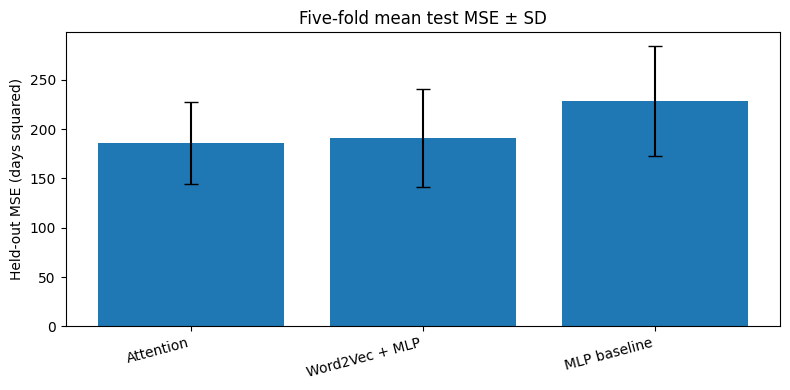

Word2Vec relative test MSE change vs MLP baseline: -16.4% (negative means improvement).


In [12]:
fig,ax=plt.subplots(figsize=(8,4))
means=results.groupby('Model')['Test MSE'].mean().sort_values()
sds=results.groupby('Model')['Test MSE'].std().reindex(means.index)
ax.bar(means.index,means.values,yerr=sds.values,capsize=5)
ax.set_ylabel('Held-out MSE (days squared)');ax.set_title('Five-fold mean test MSE ± SD')
plt.xticks(rotation=15,ha='right');plt.tight_layout();plt.savefig('MGS670_Project2_comparison.png',dpi=160);plt.show()
base=means['MLP baseline'];enhanced=means['Word2Vec + MLP']
print(f'Word2Vec relative test MSE change vs MLP baseline: {(enhanced-base)/base*100:+.1f}% (negative means improvement).')


### Discussion guide (populate with actual outputs above)
1. **Tuning:** Report which widths/dropouts/learning rates were selected across folds; note any variance.
2. **Attention advantage:** Compare the five-fold test MSE and SD of attention with the baseline MLP. Attention may capture feature interactions but adds complexity; do not claim temporal learning.
3. **Assumptions:** HLOS is a positive, observed continuous outcome; admission-time predictors are available at prediction; missing values are imputed; censoring symbols are approximated by their numerical bounds; records are independent at the patient level.
4. **Hard-coded parameters:** Five folds, 24-dimensional Word2Vec vectors, window 4, 40 embedding epochs, random seed 42, training epochs up to 55, batch size 64, patience 9, and the candidate tuning grid.
5. **Comorbidities Other:** Calculate percent change in mean test MSE for Word2Vec + MLP relative to MLP baseline. The addition does **not** necessarily improve results.

